In [ ]:
#nom du fichier choisi: https://www.kaggle.com/datasets/vedauv/what-makes-a-song-go-viral-10000-tracks

import pandas as pd 
import matplotlib.pyplot as plt
df = pd.read_csv("C:/Users/afons/cours-info/viral_songs.csv") #à remplaçer
df

# L'objectif de l'étude de ce dataset va être de savoir comment faire un hit

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,track_09996,Track_09996,Artist_1357,Latin,2011,184,0.786,0.774,0.778,91.4,0.000,0.216,0.273,0.287,-6.35,1865425,1
9996,track_09997,Track_09997,Artist_0123,Classical,2012,165,0.463,0.381,0.631,79.0,0.943,0.000,0.215,0.178,-8.22,186073,0
9997,track_09998,Track_09998,Artist_0504,Rock,2014,242,0.567,0.842,0.611,132.1,0.384,0.124,0.203,0.344,-11.01,55762,0
9998,track_09999,Track_09999,Artist_0801,Hip-Hop,2012,165,0.815,0.901,0.569,91.2,0.124,0.000,0.125,0.061,-7.52,3710114,1


In [4]:
df.describe()

,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04,10000.00000
mean,2017.499400,208.776800,0.611709,0.651938,0.582280,110.975940,0.295583,0.177337,0.087453,0.184925,-7.975896,2.415685e+06,0.36050
std,4.607854,49.967024,0.192612,0.187686,0.177984,19.017206,0.263574,0.161221,0.069674,0.114307,2.976277,9.721026e+06,0.48017
min,2010.000000,60.000000,0.000000,0.005000,0.000000,50.000000,0.000000,0.000000,0.000000,0.000000,-18.740000,1.340000e+02,0.00000
25%,2013.000000,175.000000,0.482000,0.529000,0.459000,98.000000,0.085000,0.017000,0.027000,0.099000,-9.980000,8.671450e+04,0.00000
50%,2018.000000,209.000000,0.624000,0.669000,0.582000,111.300000,0.235000,0.154000,0.080000,0.180000,-7.980000,3.290580e+05,0.00000
75%,2022.000000,242.000000,0.753000,0.787000,0.703000,124.500000,0.441000,0.288000,0.134000,0.264000,-5.990000,1.343092e+06,1.00000
max,2025.000000,433.000000,1.000000,1.000000,1.000000,177.800000,1.000000,0.934000,0.381000,0.623000,0.000000,4.430683e+08,1.00000


In [5]:
# On constate que l'on a des sons publiées entre 2010 et 2025
# et plein d'autres choses 

In [53]:
len(df['artist'].unique())

1987

In [ ]:
# Il y a 1987 artistes différents parmi les 10 000 sons

In [6]:
# On cherche quel genre de musique est le plus viral
hit_par_an_et_genre = pd.pivot_table(
    df,
    values = 'viral',
    index = 'genre',
    columns = 'release_year',
    aggfunc = 'sum')
hit_par_an_et_genre


release_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
genre,,,,,,,,,,,,,,,,
Classical,3,2,1,0,1,0,0,0,3,0,0,0,0,1,1,0
Country,11,16,14,10,14,16,16,14,18,11,16,19,17,5,17,11
Electronic,31,31,25,33,35,29,34,32,32,42,33,33,27,27,21,37
Hip-Hop,48,44,38,49,42,40,31,36,37,35,43,41,44,42,34,39
Indie,6,9,11,3,13,12,7,8,9,7,6,11,7,9,12,8
Jazz,3,5,5,6,4,4,3,0,4,4,6,1,2,9,3,2
Latin,39,39,30,40,40,46,49,25,40,49,56,42,43,48,37,43
Pop,36,28,36,40,43,51,32,38,31,37,41,39,37,46,41,43
R&B,16,23,30,24,33,21,15,19,22,28,24,22,36,35,21,16


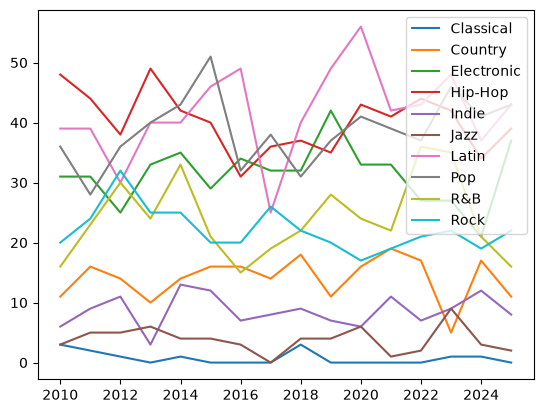

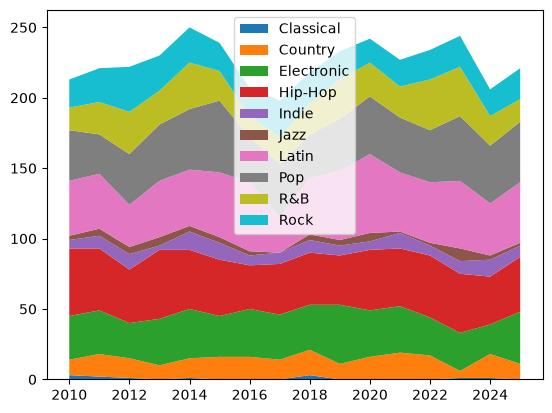

In [7]:
an = hit_par_an_et_genre.columns
style = hit_par_an_et_genre.index
for i in style:
    plt.plot(an,hit_par_an_et_genre.loc[i],label = i)
    plt.legend()
plt.show()

plt.stackplot(an,hit_par_an_et_genre.values,labels = hit_par_an_et_genre.index)
plt.legend()
plt.show()           

In [ ]:
#certains genre produisent peu de hit depuis 15 ans : classique, jazz, indie
#alors si on veut faire un hit il serait préférable de faire de la pop, des musiques latines ou bien du Hip - Hop

In [ ]:
# On s'intéresse désormais au BPM

In [8]:
bpm_par_genre = pd.pivot_table(
    df,
    values="tempo_bpm",
    index="viral",
    columns="genre")
bpm_par_genre

genre,Classical,Country,Electronic,Hip-Hop,Indie,Jazz,Latin,Pop,R&B,Rock
viral,,,,,,,,,,
0,94.324923,113.591213,127.506339,93.173594,120.715205,110.889159,105.031868,118.938903,99.839292,123.697123
1,92.458333,116.717333,127.647211,93.609331,120.855072,108.009836,105.874324,119.007431,99.649091,124.613559


In [ ]:
#globalement le bpm est lié au genre et non à la viralité: on observe une moyenne de BPM similaire 
#pour les musiques virales et non virales d'un même genre

In [1]:
# conclusion le bpm ne nous apporte pas d'infos sur la viralité si nous avons déjà le genre donc on l'enlève de notre tableau 
del df['tempo_bpm']
df

NameError: name 'df' is not defined

In [9]:
#On va aussi garder que les musiques des 3 genres cités précèdement
df_PLH = df[(df['genre'] == 'Pop') | (df['genre'] == 'Latin') | (df['genre'] == 'Hip-Hop')]
df_PLH.reset_index()

,index,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
2,4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1
3,8,track_00009,Track_00009,Artist_1555,Pop,2018,247,0.470,0.717,0.659,154.9,0.121,0.210,0.077,0.040,-4.57,384920,1
4,9,track_00010,Track_00010,Artist_0697,Latin,2015,191,0.969,0.917,0.648,106.2,0.076,0.335,0.217,0.285,-7.97,155044,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3079,9989,track_09990,Track_09990,Artist_0697,Latin,2023,206,0.676,0.682,0.884,98.6,0.271,0.252,0.006,0.176,-5.18,77836,0
3080,9991,track_09992,Track_09992,Artist_0138,Latin,2025,200,0.626,0.955,0.695,103.0,0.210,0.095,0.114,0.166,-8.62,14025047,1
3081,9992,track_09993,Track_09993,Artist_1606,Pop,2014,184,0.573,0.626,0.431,133.4,0.166,0.415,0.013,0.039,-5.01,2295310,0
3082,9995,track_09996,Track_09996,Artist_1357,Latin,2011,184,0.786,0.774,0.778,91.4,0.000,0.216,0.273,0.287,-6.35,1865425,1


In [10]:
 # On s'interesse à la dancabilité et l'énergie des sons
dancabilite_energie_par_genre = pd.pivot_table(
    df_PLH,
    values=["danceability","energy"],
    index="viral",
    columns="genre")
dancabilite_energie_par_genre

danceability                        energy                    
genre      Hip-Hop     Latin       Pop   Hip-Hop     Latin       Pop
viral                                                               
0         0.768895  0.784637  0.681671  0.676235  0.732816  0.708339
1         0.793030  0.810077  0.709675  0.687114  0.762788  0.729320

In [ ]:
#on s'intéresse à la "dançabilité" et à l'énergie de chaque musique. Il est clair 
#que les sons viraux sont plus énergétiques, et plus "dançables" peu importe le genre
#PS il faut savoir que les valeurs du tableau sont comprises dans [0,1]

In [11]:
# On s'interesse à la durée des sons
A = pd.cut(df_PLH['duration_sec'], 
       bins = [60,134,208,282,356,433],
       labels = ['très court','court','moyen','long','très long'])
#On découpe l'intervalle de temps trouvé en 5, et on cherche quelle durée est la meilleure pour produire un hit

df_PLH['durée_son'] = A

durée_globale_son = pd.pivot_table(
    df_PLH,
    values=['viral'],
    index=["durée_son"],
    columns="genre")
durée_globale_son

viral                    
genre        Hip-Hop     Latin       Pop
durée_son                               
très court  0.584615  0.526316  0.662651
court       0.584946  0.649462  0.593137
moyen       0.642222  0.646667  0.624709
long        0.590909  0.754386  0.671053
très long   0.800000       NaN  0.500000

In [1]:
# En conclusion pour faire un hit il faut faire une musique "dançabilité", avec de l'énergie et surtout 
# il faut choisir un des 3 genre suivant : Hip Hop, Latin ou Pop